In [1]:
import torch
import json
from src.utils import set_seed
from src.data_loader import get_dataloaders
from src.model import JointBiLSTMAttention
from src.metrics import evaluate_model
from src.train import train

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

with open('params.json', 'r') as f:
    params = json.load(f)

Using device: cpu


In [2]:
# 1. Load Data & Assert Splits
loaders, vocab, embedding_matrix = get_dataloaders(
    data_path='1.0/data/en-US.jsonl',
    batch_size=params.get('batch_size', 32),
    embedding_dim=params.get('embedding_dim', 300)
)
train_loader = loaders['train']
dev_loader = loaders['dev']
test_loader = loaders['test']
id2slot = {v: k for k, v in vocab.slot2id.items()}

print("Asserting Official Dataset Splits...")
assert len(train_loader.dataset) == 11514, f"Expected 11514 Train, got {len(train_loader.dataset)}"
assert len(dev_loader.dataset) == 2033, f"Expected 2033 Dev, got {len(dev_loader.dataset)}"
assert len(test_loader.dataset) == 2974, f"Expected 2974 Test, got {len(test_loader.dataset)}"
print("Dataset Split Integrity Verified: 11,514 Train | 2,033 Dev | 2,974 Test")

Asserting Official Dataset Splits...
Dataset Split Integrity Verified: 11,514 Train | 2,033 Dev | 2,974 Test


In [3]:
# 2. Initialize Model & Verify Parameter Budget
model = JointBiLSTMAttention(
    vocab_size=len(vocab.word2id),
    embedding_dim=params.get('embedding_dim', 300),
    hidden_dim=params.get('hidden_dim', 256),
    num_intents=len(vocab.intent2id),
    num_slots=len(vocab.slot2id),
    dropout=params.get('dropout', 0.3),
    slot_loss_weight=params.get('slot_loss_weight', 1.0),
    embedding_matrix=embedding_matrix,
    id2slot=id2slot
).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total Model Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

assert total_params <= 20000000, "CRITICAL FAIL: Model exceeds 20M parameter limit!"
print("Parameter ceiling verified: <= 20M parameters.")

Total Model Parameters: 4,409,461
Trainable Parameters: 4,409,461
Parameter ceiling verified: <= 20M parameters.


Total Model Parameters: 4409461

Starting Baseline Training...


Epoch 1/10 [Train]: 100%|██████████| 360/360 [00:27<00:00, 13.27it/s, loss=7.2821] 


Epoch 1 | Time: 29.43s | Train Loss: 8.8856 | Val Loss: 6.5197
Val Intent Acc: 18.64% | Val Slot F1: 9.27% | Combined: 13.95%
*** Peak Validation Score! Checkpoint saved to experiments/baseline/best_checkpoint.pt ***


Epoch 2/10 [Train]: 100%|██████████| 360/360 [00:29<00:00, 12.24it/s, loss=4.5517]


Epoch 2 | Time: 31.46s | Train Loss: 5.2091 | Val Loss: 4.0034
Val Intent Acc: 50.86% | Val Slot F1: 19.59% | Combined: 35.22%
*** Peak Validation Score! Checkpoint saved to experiments/baseline/best_checkpoint.pt ***


Epoch 3/10 [Train]: 100%|██████████| 360/360 [00:23<00:00, 15.09it/s, loss=3.3506]


... (11 outputs left out)

Epoch 9/10 [Train]: 100%|██████████| 360/360 [00:24<00:00, 14.76it/s, loss=1.6642]


Epoch 9 | Time: 26.73s | Train Loss: 0.6590 | Val Loss: 2.5126
Val Intent Acc: 81.11% | Val Slot F1: 43.71% | Combined: 62.41%
*** Peak Validation Score! Checkpoint saved to experiments/baseline/best_checkpoint.pt ***


Epoch 10/10 [Train]: 100%|██████████| 360/360 [00:23<00:00, 15.01it/s, loss=0.5060]


Epoch 10 | Time: 27.38s | Train Loss: 0.5500 | Val Loss: 2.5941
Val Intent Acc: 81.36% | Val Slot F1: 47.03% | Combined: 64.19%
*** Peak Validation Score! Checkpoint saved to experiments/baseline/best_checkpoint.pt ***

TRAINING COMPLETED
Optimal Epoch Index: 10
Highest Validation Score (Combined): 64.19%
Saved Checkpoint Filename: experiments/baseline/best_checkpoint.pt


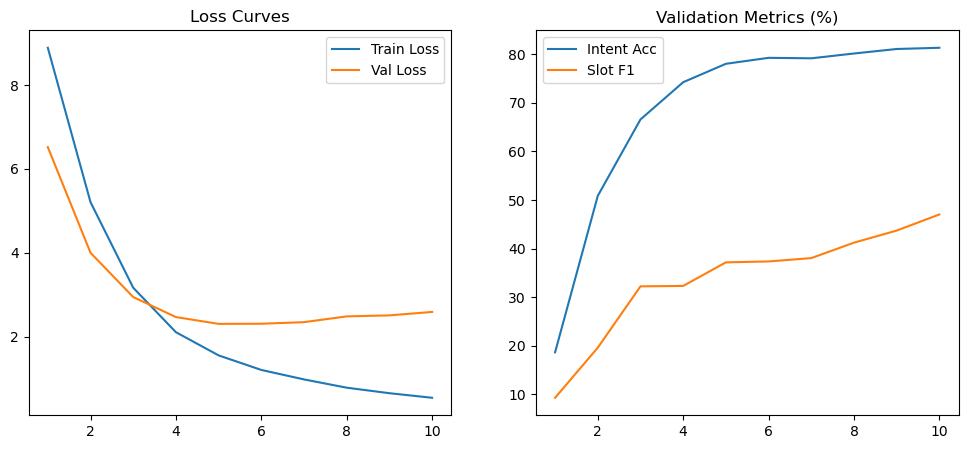

In [4]:
# 3. Train Model
train()

In [5]:
# 4. Grading Mandate: Validation Consistency & Test Evaluation
checkpoint_path = 'experiments/baseline/best_checkpoint.pt'
checkpoint = torch.load(checkpoint_path, map_location=device)

# Load frozen weights into a fresh model instance
frozen_model = JointBiLSTMAttention(
    vocab_size=len(vocab.word2id),
    embedding_dim=params.get('embedding_dim', 300),
    hidden_dim=params.get('hidden_dim', 256),
    num_intents=len(vocab.intent2id),
    num_slots=len(vocab.slot2id),
    dropout=params.get('dropout', 0.3),
    slot_loss_weight=params.get('slot_loss_weight', 1.0),
    embedding_matrix=embedding_matrix,
    id2slot=id2slot
).to(device)

frozen_model.load_state_dict(checkpoint['model_state_dict'])
frozen_model.eval()

print(f"Reloaded Checkpoint from Epoch {checkpoint['epoch']}")
print(f"Original Peak Validation Score: {checkpoint['validation_score']:.2f}%")

print("\nRe-evaluating on Dev Split...")
dev_metrics = evaluate_model(frozen_model, dev_loader, device, id2slot)
print(f"Reloaded Dev Intent Acc: {dev_metrics['intent_accuracy']:.2f}%")
print(f"Reloaded Dev Slot F1: {dev_metrics['slot_micro_f1']:.2f}%")
print(f"Reloaded Dev Combined: {dev_metrics['combined_score']:.2f}%")

assert dev_metrics['combined_score'] == checkpoint['validation_score'], "Consistency Error: Reloaded score does not match training peak!"
print("Validation Consistency Verified.")

print("\nEvaluating on Official Test Split (2,974 examples)...")
test_metrics = evaluate_model(frozen_model, test_loader, device, id2slot)
print(f"TEST INTENT ACCURACY: {test_metrics['intent_accuracy']:.2f}%")
print(f"TEST SLOT MICRO-F1: {test_metrics['slot_micro_f1']:.2f}%")

Reloaded Checkpoint from Epoch 10
Original Peak Validation Score: 64.19%

Re-evaluating on Dev Split...
Reloaded Dev Intent Acc: 81.36%
Reloaded Dev Slot F1: 47.03%
Reloaded Dev Combined: 64.19%
Validation Consistency Verified.

Evaluating on Official Test Split (2,974 examples)...
TEST INTENT ACCURACY: 80.73%
TEST SLOT MICRO-F1: 43.73%
